**Q1. Portfolio Return**

**(a) Equal-Weighted Index (Weekly Rebalancing)**

/tmp/ipykernel_288/2324304321.py:11: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df['prc'] = df['prc'].fillna(method='ffill')


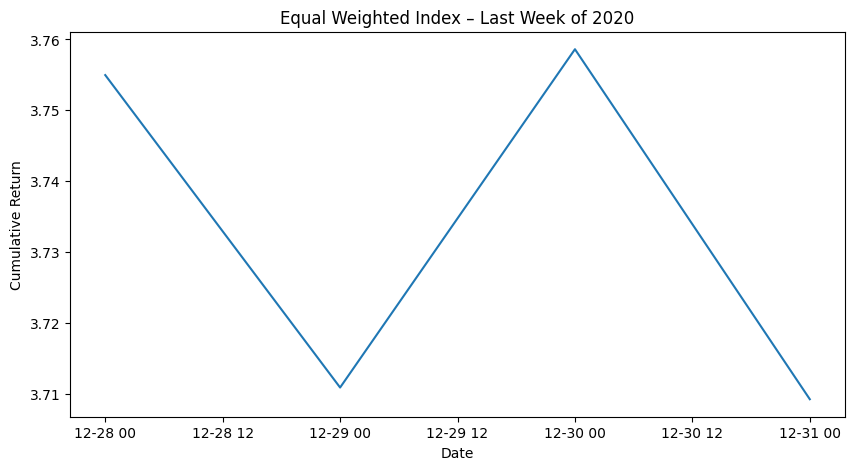

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# load data
df = pd.read_csv('crsp_sample.csv')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values(['permno','date'])

# handle missing data
df['ret'] = df['ret'].fillna(0)
df['prc'] = df['prc'].fillna(method='ffill')

# create week identifier
df['week'] = df['date'].dt.to_period('W')

# equal weights (computed once per week)
n_stocks = df.groupby(['date'])['permno'].transform('count')
df['weight_eq'] = 1 / n_stocks

# portfolio return
df['weighted_ret_eq'] = df['weight_eq'] * df['ret']
daily_index_eq = df.groupby('date')['weighted_ret_eq'].sum()

# cumulative return
cum_eq = (1 + daily_index_eq).cumprod()

# plot last week of 2020
plt.figure(figsize=(10,5))
plt.plot(cum_eq['2020-12-28':'2020-12-31'])
plt.title('Equal Weighted Index – Last Week of 2020')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.show()

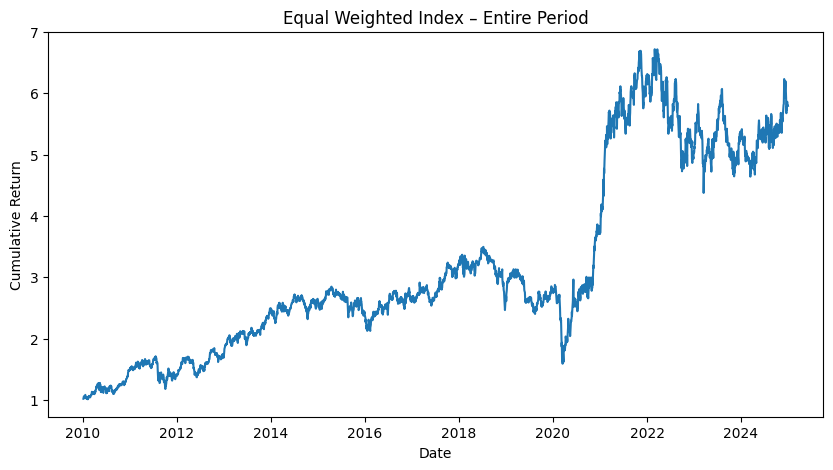

In [2]:
# plot full period
plt.figure(figsize=(10,5))
plt.plot(cum_eq)
plt.title('Equal Weighted Index – Entire Period')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.show()

**(b) Value-Weighted Index (Weekly Rebalancing)**

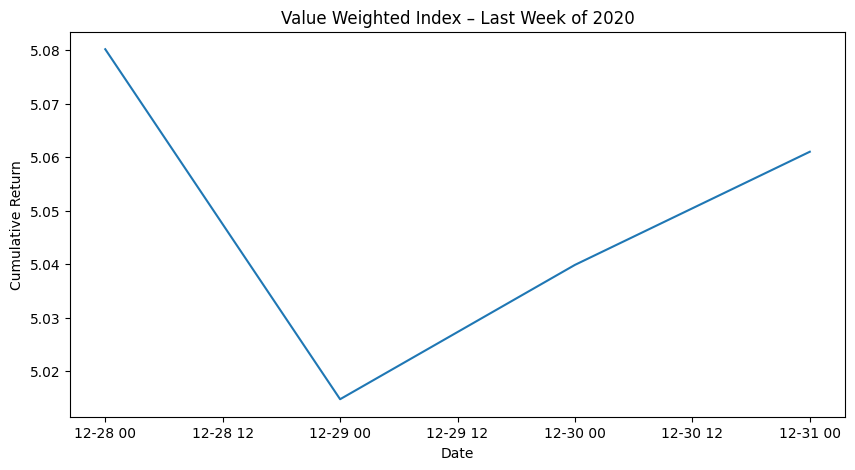

In [3]:
# compute market cap
df['mktcap'] = df['prc'].abs() * df['shrout']

# identify week
df['week'] = df['date'].dt.to_period('W')

# first trading day of each week
week_start = df.groupby(['permno','week'])['date'].transform('min')
df['week_start'] = df['date'] == week_start

# total market cap on rebalance day
df.loc[df['week_start'], 'total_mktcap'] = (
    df[df['week_start']].groupby('date')['mktcap'].transform('sum')
)

# forward fill within week
df['total_mktcap'] = df.groupby('week')['total_mktcap'].ffill()

# compute weights
df['weight_vw'] = df['mktcap'] / df['total_mktcap']

# portfolio return
df['weighted_ret_vw'] = df['weight_vw'] * df['ret']
daily_index_vw = df.groupby('date')['weighted_ret_vw'].sum()

# cumulative return
cum_vw = (1 + daily_index_vw).cumprod()

# plot last week of 2020
plt.figure(figsize=(10,5))
plt.plot(cum_vw['2020-12-28':'2020-12-31'])
plt.title('Value Weighted Index – Last Week of 2020')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.show()

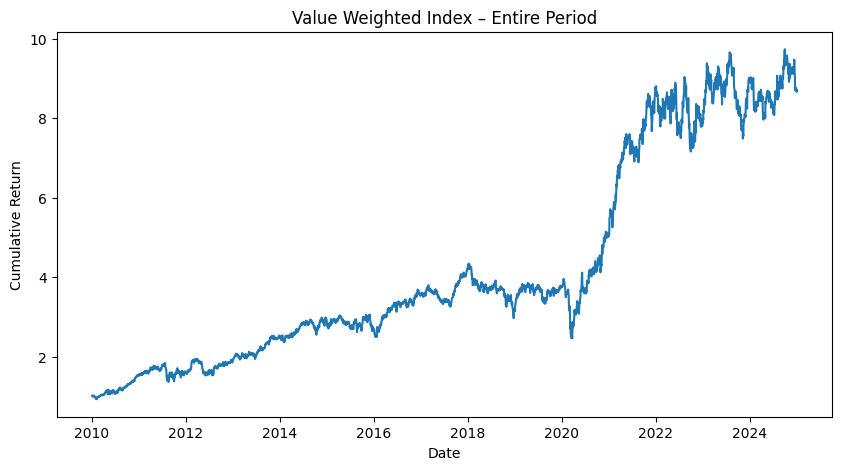

In [4]:
# plot full period
plt.figure(figsize=(10,5))
plt.plot(cum_vw)
plt.title('Value Weighted Index – Entire Period')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.show()